# kino.lensing: the misalignment signal

**Scope note.** Like the earlier demo notebooks, this one runs today and
demonstrates `kino.lensing` (Phase 2): applying a known reduced shear
`(g1, g2)` to a `DiscGalaxy` scene. No instrument or inference yet -- this
is pure forward-model geometry.

**Why this plot is the KL method, in one picture.** Lensing remaps sky
position identically for the image and the velocity field (`CLAUDE.md`:
shear must hit both). Naively you might expect the photometric shape and
the kinematic axis to stay aligned, since they go through the *same*
coordinate remap. They don't, because they respond to that remap
differently: the photometric shape depends on the *symmetric* part of the
combined (inclination-projection) x (shear) transform, while the kinematic
axis is a *specific direction* (the disc's line of nodes) carried through
that same transform. Projection and shear don't commute in general, so the
two axes drift apart -- and the drift *is* the shear signal. This is
exactly the plot kinematic-lensing papers show: a velocity field with the
photometric major axis overplotted, visibly not tracking the
kinematic (zero-velocity-line) axis.

We'll:
1. Shear a `DiscGalaxy` and show the classic panel: lensed image + fitted
   photometric ellipse, next to the lensed velocity field with both the
   true kinematic axis and the photometric axis overplotted.
2. Contrast with the zero-shear case, where the two axes exactly coincide.
3. Sweep the shear's orientation relative to the disc's own axes and show
   the misalignment angle vanishes at alignment and rises in between
   -- purely analytically, no image rendering needed.

Requires the `data` extra only indirectly (not used here) -- just
`pip install -e ".[dev,notebooks]"`.

## 0. Setup

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Ellipse

import kino
from kino.galaxy import DiscGalaxy
from kino.lensing import apply_shear
from kino.lensing.moments import measure_ellipticity

print("kino", kino.__version__)

kino 0.1.0.dev0


## 1. Helpers: axis lines and the misalignment angle

A position angle line through the centroid, and the (mod-180) angular
difference between two position angles.

In [2]:
def pa_line(pa_deg, x0, y0, length):
    pa_rad = np.radians(pa_deg)
    dx, dy = length * np.sin(pa_rad), length * np.cos(pa_rad)
    return (x0 - dx, x0 + dx), (y0 - dy, y0 + dy)


def misalignment(pa_a, pa_b):
    """Smallest angular difference between two mod-180 position angles, degrees."""
    diff = (pa_a - pa_b + 90.0) % 180.0 - 90.0
    return abs(diff)

## 2. Shear a disc and measure both axes

The galaxy's `pa=20` deg is the **true kinematic axis** -- what a kinematic
model (in the real method: Vmax + Tully-Fisher) would recover, unaffected
by the spatial shear distortion. The **photometric axis** is measured from
the actual (lensed) image pixels.

In [3]:
gal = DiscGalaxy(r_e=2.5, inc=55.0, pa=20.0, v_flat=180.0, r_t=2.0)
g1, g2 = 0.18, 0.12  # not aligned with pa=20 -- see the sweep in section 4 for why this matters
scene = apply_shear(gal, g1, g2)

extent = 8 * gal.r_e
coords = np.linspace(-extent, extent, 300)
x, y = np.meshgrid(coords, coords)

image = scene.surface_brightness(x, y)
vel_map = scene.vlos(x, y)

xbar, ybar, eps1, eps2, a, b = measure_ellipticity(image, x, y)
measured_mag = np.hypot(eps1, eps2)
measured_phi = 0.5 * np.arctan2(eps2, eps1)
pa_phot = np.degrees(np.pi / 2.0 - measured_phi) % 180.0

pa_kin = gal.pa
mis = misalignment(pa_phot, pa_kin)
print(f"kinematic PA (true):        {pa_kin:.2f} deg")
print(f"photometric PA (measured):  {pa_phot:.2f} deg")
print(f"misalignment:               {mis:.2f} deg")
print(f"photometric ellipticity:    {measured_mag:.3f} (intrinsic was {gal.ellipticity:.3f})")

kinematic PA (true):        20.00 deg
photometric PA (measured):  43.96 deg
misalignment:               23.96 deg
photometric ellipticity:    0.300 (intrinsic was 0.271)


## 3. The plot

Left: the lensed image, zoomed to the fitted photometric ellipse, with both
its axes (major dashed, minor dotted). Right: the lensed velocity field,
zoomed the same way, faded outside that same ellipse so the photometric
shape stands out against it -- with **both** pairs of axes drawn: solid
for the true kinematic major/minor axes, cyan for the photometric
major/minor axes (the same ellipse from the left panel). The angle between
the solid and cyan pairs is the shear signal.


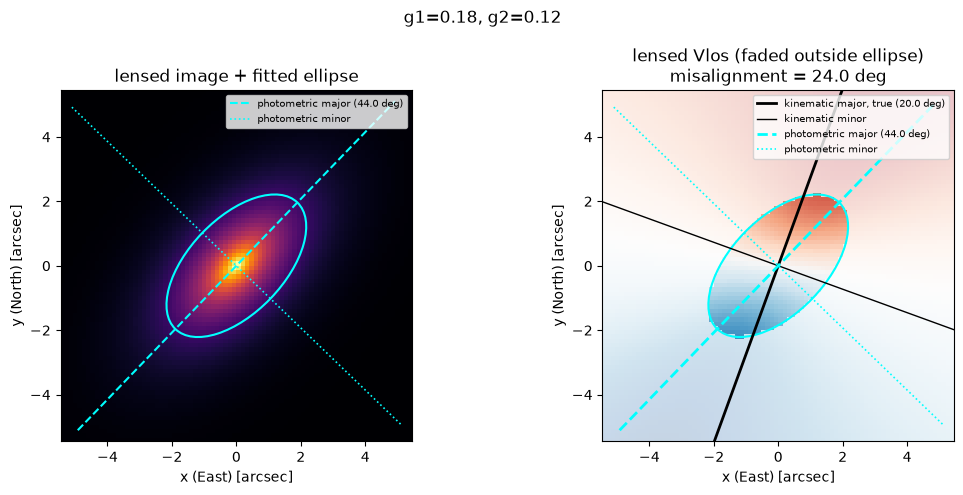

In [4]:
def ellipse_mask(xg, yg, xc, yc, a_ax, b_ax, phi_rad):
    """True where (xg, yg) falls inside the ellipse (xc, yc, a_ax, b_ax, phi_rad)."""
    dx, dy = xg - xc, yg - yc
    x_ell = dx * np.cos(phi_rad) + dy * np.sin(phi_rad)
    y_ell = -dx * np.sin(phi_rad) + dy * np.cos(phi_rad)
    return (x_ell / a_ax) ** 2 + (y_ell / b_ax) ** 2 <= 1.0


def draw_ellipse(ax, xc, yc, a_ax, b_ax, phi_rad, **kwargs):
    ax.add_patch(
        Ellipse((xc, yc), width=2 * a_ax, height=2 * b_ax, angle=np.degrees(phi_rad), **kwargs)
    )


zoom = 2.0 * a  # zoom in so the ellipse fills most of the panel
inside = ellipse_mask(x, y, xbar, ybar, a, b, measured_phi)
axis_len = zoom * 1.3

fig, axes = plt.subplots(1, 2, figsize=(11, 5))

# --- left: image, zoomed, ellipse + both its axes ---
axes[0].imshow(image, origin="lower", extent=[-extent, extent, -extent, extent], cmap="inferno")
draw_ellipse(axes[0], xbar, ybar, a, b, measured_phi, edgecolor="cyan", facecolor="none", lw=1.5)
xline, yline = pa_line(pa_phot, xbar, ybar, axis_len)
xline_m, yline_m = pa_line(pa_phot + 90, xbar, ybar, axis_len)
axes[0].plot(
    xline, yline, "--", color="cyan", lw=1.5, label=f"photometric major ({pa_phot:.1f} deg)"
)
axes[0].plot(xline_m, yline_m, ":", color="cyan", lw=1.2, label="photometric minor")
axes[0].set_title("lensed image + fitted ellipse")
axes[0].legend(loc="upper right", fontsize=7)

# --- right: Vlos, faded outside the ellipse, both axis pairs ---
vmax = np.abs(vel_map).max()
imshow_kwargs = dict(
    origin="lower", extent=[-extent, extent, -extent, extent], cmap="RdBu_r", vmin=-vmax, vmax=vmax
)
axes[1].imshow(vel_map, alpha=0.25, **imshow_kwargs)  # faded background, whole field
vel_inside = np.ma.array(vel_map, mask=~inside)
axes[1].imshow(vel_inside, **imshow_kwargs)  # full strength, ellipse interior only
draw_ellipse(axes[1], xbar, ybar, a, b, measured_phi, edgecolor="cyan", facecolor="none", lw=1.5)

xline_kin, yline_kin = pa_line(pa_kin, gal.x0, gal.y0, axis_len)
xline_kin_m, yline_kin_m = pa_line(pa_kin + 90, gal.x0, gal.y0, axis_len)
xline_phot, yline_phot = pa_line(pa_phot, xbar, ybar, axis_len)
xline_phot_m, yline_phot_m = pa_line(pa_phot + 90, xbar, ybar, axis_len)
axes[1].plot(
    xline_kin, yline_kin, "-", color="k", lw=2, label=f"kinematic major, true ({pa_kin:.1f} deg)"
)
axes[1].plot(xline_kin_m, yline_kin_m, "-", color="k", lw=1, label="kinematic minor")
axes[1].plot(
    xline_phot, yline_phot, "--", color="cyan", lw=2, label=f"photometric major ({pa_phot:.1f} deg)"
)
axes[1].plot(xline_phot_m, yline_phot_m, ":", color="cyan", lw=1.2, label="photometric minor")
axes[1].set_title(f"lensed Vlos (faded outside ellipse)\nmisalignment = {mis:.1f} deg")
axes[1].legend(loc="upper right", fontsize=7)

for ax in axes:
    ax.set_xlim(xbar - zoom, xbar + zoom)
    ax.set_ylim(ybar - zoom, ybar + zoom)
    ax.set_xlabel("x (East) [arcsec]")
    ax.set_ylabel("y (North) [arcsec]")
fig.suptitle(f"g1={g1}, g2={g2}")
fig.tight_layout()

## 4. Contrast: zero shear, axes coincide exactly

With no shear, the photometric and kinematic axes must agree -- there's
nothing left to misalign.

g=0: kinematic PA = 20.000 deg, photometric PA = 20.002 deg, misalignment = 0.0018 deg


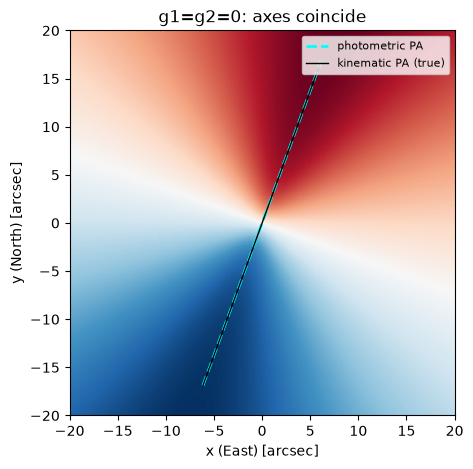

In [5]:
scene0 = apply_shear(gal, 0.0, 0.0)
image0 = scene0.surface_brightness(x, y)
vel_map0 = scene0.vlos(x, y)

_, _, eps1_0, eps2_0, a0, b0 = measure_ellipticity(image0, x, y)
pa_phot0 = np.degrees(np.pi / 2.0 - 0.5 * np.arctan2(eps2_0, eps1_0)) % 180.0
print(
    f"g=0: kinematic PA = {pa_kin:.3f} deg, photometric PA = {pa_phot0:.3f} deg, "
    f"misalignment = {misalignment(pa_phot0, pa_kin):.4f} deg"
)

fig, ax = plt.subplots(figsize=(5, 5))
L = extent * 0.9
vmax0 = np.abs(vel_map0).max()
ax.imshow(
    vel_map0,
    origin="lower",
    extent=[-extent, extent, -extent, extent],
    cmap="RdBu_r",
    vmin=-vmax0,
    vmax=vmax0,
)
xline0, yline0 = pa_line(pa_phot0, gal.x0, gal.y0, L)
ax.plot(xline0, yline0, "--", color="cyan", lw=2, label="photometric PA")
xline_k0, yline_k0 = pa_line(pa_kin, gal.x0, gal.y0, L)
ax.plot(xline_k0, yline_k0, "-", color="k", lw=1, label="kinematic PA (true)")
ax.legend(loc="upper right", fontsize=8)
ax.set_title("g1=g2=0: axes coincide")
ax.set_xlabel("x (East) [arcsec]")
ax.set_ylabel("y (North) [arcsec]");

## 5. Misalignment vs. shear orientation

Fix `|g|` and sweep the shear's own orientation relative to the disc.
`tests/lensing/test_scene.py::test_misalignment_vanishes_when_shear_aligned_with_disc_axes`
proves the zero analytically; this traces out the full curve. Computed
purely from `LensedScene.photometric_ellipticity` -- no image rendering
needed for this panel.

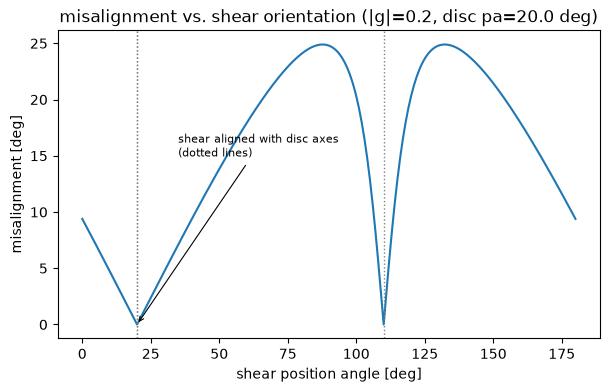

In [6]:
def shear_from_position_angle(mag, shear_pa_deg):
    phi = np.pi / 2.0 - np.radians(shear_pa_deg)
    g = mag * np.exp(2j * phi)
    return g.real, g.imag


shear_pas = np.linspace(0, 180, 361)
mag = 0.2
mis_curve = []
for spa in shear_pas:
    sg1, sg2 = shear_from_position_angle(mag, spa)
    _, pa_p = apply_shear(gal, sg1, sg2).photometric_ellipticity
    mis_curve.append(misalignment(pa_p, gal.pa))

plt.figure(figsize=(7, 4))
plt.plot(shear_pas, mis_curve)
for offset in (0, 90, 180):
    plt.axvline((gal.pa + offset) % 180, color="gray", ls=":", lw=1)
plt.xlabel("shear position angle [deg]")
plt.ylabel("misalignment [deg]")
plt.title(f"misalignment vs. shear orientation (|g|={mag}, disc pa={gal.pa} deg)")
plt.annotate(
    "shear aligned with disc axes\n(dotted lines)",
    xy=(gal.pa, 0),
    xytext=(gal.pa + 15, max(mis_curve) * 0.6),
    fontsize=8,
    arrowprops=dict(arrowstyle="->", lw=0.8),
);

The misalignment is exactly zero at the disc's own major and minor axes
(the dotted lines, `pa` and `pa+90`) and rises in between -- shear along
the disc's own axes only rescales its ellipticity; shear at any other
angle also rotates it, pulling the photometric axis away from the
(shear-invariant) kinematic one. Where exactly the peak sits between the
two zeros depends on the disc's intrinsic ellipticity and `|g|`, not a
fixed 45 degrees.


## 6. A Pranjal-style figure (arXiv:2409.08367, Figure 1)

Reproducing (not pixel-for-pixel, but the same idea) the paper's Figure 1:
*"In the source frame, the velocity field (filled contours) is symmetric
about the photometric major and minor axis (dashed black lines) ... The
application of shear distorts the isophote and breaks the symmetry in the
velocity field."*

Left: the unlensed ("source frame") scene -- filled `Vlos` contours, the
photometric isophote (a contour of the image itself, so it's whatever
shape the data actually have -- no assumption baked in), and the major and
minor axes as dashed lines. Right: the same scene lensed. Open squares
mark a fixed radius along the *photometric* major axis of each panel; open
circles the same along the minor axis, with the `Vlos` value at each point
printed in the title -- on the left these are (by construction) the
extremum and zero directions; on the right, because the photometric axes
have rotated but the velocity field's true symmetry axis (the kinematic
`pa`) hasn't, neither marker sits on an extremum or a zero any more. That
gap between "photometric axis" and "where the velocity field actually
peaks or vanishes" is the same misalignment as sections 2-5, just drawn in
the paper's style.

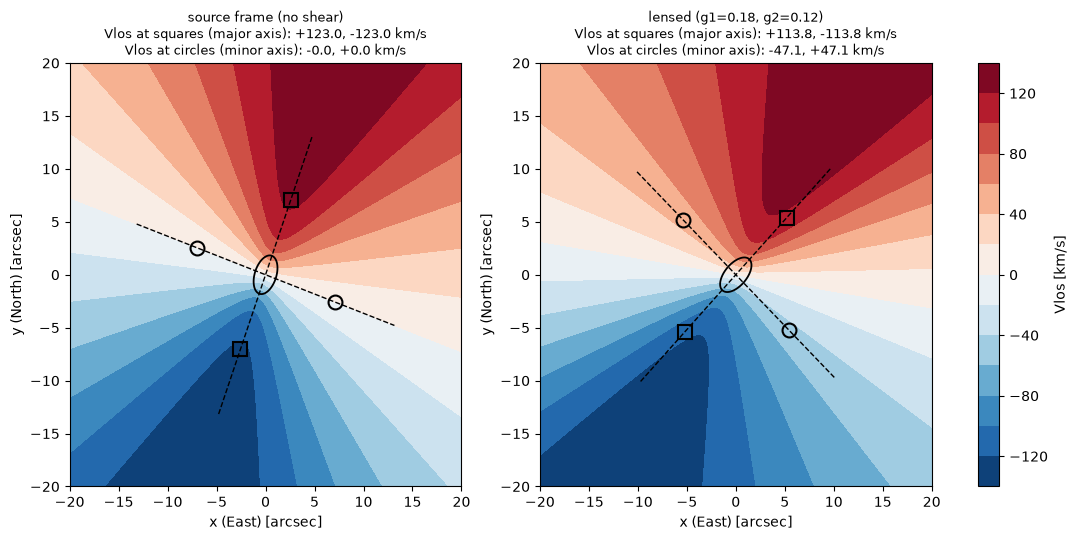

In [7]:
def photometric_axes(pa_deg):
    pa_rad = np.radians(pa_deg)
    major = np.array([np.sin(pa_rad), np.cos(pa_rad)])
    minor = np.array([np.cos(pa_rad), -np.sin(pa_rad)])
    return major, minor


centroid = np.array([gal.x0, gal.y0])
r_mark = 3.0 * gal.r_e
iso_level = 0.3 * image0.max()
vmax_shared = max(np.abs(vel_map0).max(), np.abs(vel_map).max())

panels = [
    (scene0, image0, vel_map0, pa_phot0, "source frame (no shear)"),
    (scene, image, vel_map, pa_phot, f"lensed (g1={g1}, g2={g2})"),
]

fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
for ax, (sc, img, vel, pa, title) in zip(axes, panels, strict=True):
    cf = ax.contourf(x, y, vel, levels=15, cmap="RdBu_r", vmin=-vmax_shared, vmax=vmax_shared)
    ax.contour(x, y, img, levels=[iso_level], colors="k", linewidths=1.3)

    xline, yline = pa_line(pa, gal.x0, gal.y0, extent * 0.7)
    xline_m, yline_m = pa_line(pa + 90, gal.x0, gal.y0, extent * 0.7)
    ax.plot(xline, yline, "k--", lw=1)
    ax.plot(xline_m, yline_m, "k--", lw=1)

    major, minor = photometric_axes(pa)
    v_major_vals, v_minor_vals = [], []
    for sign in (+1, -1):
        p_major = centroid + sign * major * r_mark
        p_minor = centroid + sign * minor * r_mark
        v_major_vals.append(float(sc.vlos(*p_major)))
        v_minor_vals.append(float(sc.vlos(*p_minor)))
        ax.plot(*p_major, marker="s", mfc="none", mec="k", ms=10, mew=1.5)
        ax.plot(*p_minor, marker="o", mfc="none", mec="k", ms=10, mew=1.5)

    ax.set_title(
        f"{title}\n"
        f"Vlos at squares (major axis): {v_major_vals[0]:+.1f}, {v_major_vals[1]:+.1f} km/s\n"
        f"Vlos at circles (minor axis): {v_minor_vals[0]:+.1f}, {v_minor_vals[1]:+.1f} km/s",
        fontsize=9,
    )
    ax.set_xlabel("x (East) [arcsec]")
    ax.set_ylabel("y (North) [arcsec]")

fig.colorbar(cf, ax=axes, fraction=0.023, label="Vlos [km/s]")

## What's next

- `kino.instruments` (Phase 3): turn this sheared scene into a realistic
  mock observation (PSF/LSF blurring, pixelization, noise) -- the
  misalignment survives blurring in principle, but a real measurement needs
  to extract both PAs from noisy, resolution-limited data.
- `kino.inference` (Phase 5): this notebook used the *true* kinematic PA
  directly, because we built the galaxy ourselves. A real analysis instead
  infers it from Vmax and the Tully-Fisher relation, then compares to the
  measured photometric shape -- turning this geometric picture into an
  actual per-galaxy shear estimator.